# Calibration Check: PIT Histogram + Coverage

Load the forecasts we saved earlier and check if Chronos-2 is calibrated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
forecasts = np.load("../data/forecasts.npy")
actuals = np.load("../data/actuals.npy")

print(forecasts.shape)
print(actuals.shape)

(352, 30, 11)
(352, 30)


## Pick one horizon step to check first

Our forecasts go 30 days ahead, but let's start simple and just check
the 1-day-ahead forecast (day index 0) across all our windows.
We can check further-ahead days later.

In [17]:
day = 0

quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

# forecasts shape is (num_windows, horizon, num_quantiles)
# we pick out day 0 for every window
day_forecasts = forecasts[:, day, :]   # shape: (num_windows, 9)
day_actuals = actuals[:, day]           # shape: (num_windows,)

day_forecasts.shape, day_actuals.shape

((352, 11), (352,))

## Coverage check

Chronos-2 gives us a 10th percentile and a 90th percentile forecast.
That means it's claiming an 80% prediction interval.

If it's calibrated, the actual value should fall inside that interval
about 80% of the time. Let's check.

In [24]:
lower = day_forecasts[:, 1]   # 10th percentile column (now index 1)
upper = day_forecasts[:, 9]   # 90th percentile column (now index 9)

inside_interval = (day_actuals >= lower) & (day_actuals <= upper)

empirical_coverage = inside_interval.mean()

print("claimed coverage: 80%")
print("empirical coverage:", round(empirical_coverage * 100, 1), "%")

claimed coverage: 80%
empirical coverage: 80.7 %


If empirical coverage is close to 80%, the model is well calibrated for this interval.
If it's a lot lower, the model is overconfident (intervals too narrow).
If it's a lot higher, the model is underconfident (intervals too wide).

## PIT values

Coverage only checks one interval. PIT values check the whole distribution
at once, for every forecast.

For each forecast, we ask: at what percentile does the actual value fall,
according to the model's own predicted distribution?

We only have 9 quantile points, not the full distribution, so we estimate
this by interpolating between the points we have.

In [25]:
pit_values = []

for i in range(len(day_actuals)):
    q_vals = day_forecasts[i]      # the 9 predicted values for this window
    true_val = day_actuals[i]      # what actually happened

    # interpolate: given the true value, find where it falls
    # among the predicted quantiles (as a probability between 0 and 1)
    pit = np.interp(true_val, q_vals, quantile_levels)
    pit_values.append(pit)

pit_values = np.array(pit_values)
pit_values[:10]

array([0.55387583, 0.80227965, 0.4506344 , 0.61770472, 0.13959914,
       0.92711742, 0.82826737, 0.76545214, 0.64468287, 0.49994008])

Note: np.interp clips values outside the range to 0.1 or 0.9
(it can't extrapolate past our lowest/highest quantile).
This is a simplification we should mention later, since it means our
histogram can't show values below 0.1 or above 0.9 exactly.

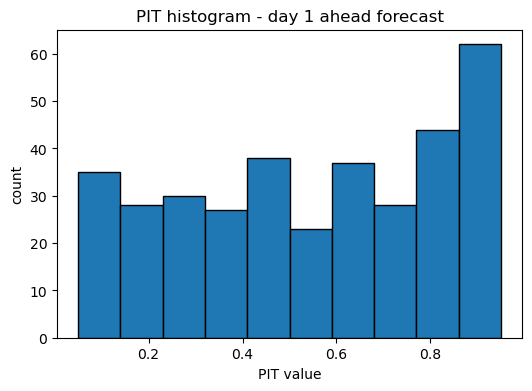

In [26]:
plt.figure(figsize=(6, 4))
plt.hist(pit_values, bins=10, edgecolor="black")
plt.xlabel("PIT value")
plt.ylabel("count")
plt.title("PIT histogram - day 1 ahead forecast")
plt.show()

## How to read this histogram

- flat / even bars across the whole range -> well calibrated
- bars piled up at the edges (0 and 1) -> model is overconfident, intervals too narrow
- bars piled up in the middle -> model is underconfident, intervals too wide
- bars leaning to one side -> model is biased in that direction

In [27]:
exactly_clipped = (pit_values == 0.9).sum()
print(exactly_clipped, "out of", len(pit_values))

0 out of 352


In [28]:
# extending quantile level
quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

In [29]:
# checking lower tail for symmetry
lower_clipped = (pit_values == 0.1).sum()
print(lower_clipped, "out of", len(pit_values))

0 out of 352


### **Checking for day=0 to day=29**

In [30]:
day = 29

quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

# forecasts shape is (num_windows, horizon, num_quantiles)
# we pick out day 0 for every window
day_forecasts = forecasts[:, day, :]   # shape: (num_windows, 9)
day_actuals = actuals[:, day]           # shape: (num_windows,)

day_forecasts.shape, day_actuals.shape

((352, 11), (352,))

In [31]:
lower = day_forecasts[:, 1]   # 10th percentile column (now index 1)
upper = day_forecasts[:, 9]   # 90th percentile column (now index 9)

inside_interval = (day_actuals >= lower) & (day_actuals <= upper)

empirical_coverage = inside_interval.mean()

print("claimed coverage: 80%")
print("empirical coverage:", round(empirical_coverage * 100, 1), "%")

claimed coverage: 80%
empirical coverage: 74.4 %


In [32]:
pit_values = []

for i in range(len(day_actuals)):
    q_vals = day_forecasts[i]      # the 9 predicted values for this window
    true_val = day_actuals[i]      # what actually happened

    # interpolate: given the true value, find where it falls
    # among the predicted quantiles (as a probability between 0 and 1)
    pit = np.interp(true_val, q_vals, quantile_levels)
    pit_values.append(pit)

pit_values = np.array(pit_values)
pit_values[:10]

array([0.81859572, 0.60644713, 0.14382499, 0.34799392, 0.3033889 ,
       0.22238642, 0.23492429, 0.2926019 , 0.69670004, 0.80413949])

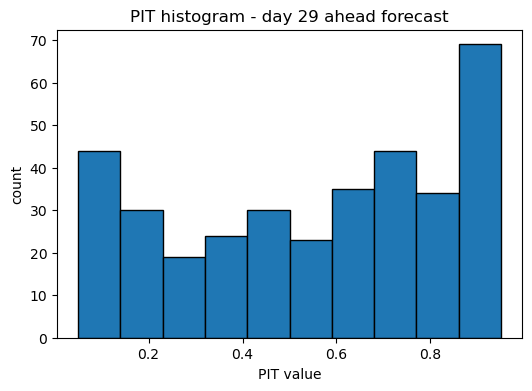

In [34]:
plt.figure(figsize=(6, 4))
plt.hist(pit_values, bins=10, edgecolor="black")
plt.xlabel("PIT value")
plt.ylabel("count")
plt.title("PIT histogram - day 29 ahead forecast")
plt.show()

### **For conformation if the decay is gradual or drastic day=29 to day=15 checking**

In [66]:
day = 15

quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

# forecasts shape is (num_windows, horizon, num_quantiles)
# we pick out day 0 for every window
day_forecasts = forecasts[:, day, :]   # shape: (num_windows, 9)
day_actuals = actuals[:, day]           # shape: (num_windows,)

day_forecasts.shape, day_actuals.shape

((352, 11), (352,))

In [67]:
lower = day_forecasts[:, 1]   # 10th percentile column (now index 1)
upper = day_forecasts[:, 9]   # 90th percentile column (now index 9)

inside_interval = (day_actuals >= lower) & (day_actuals <= upper)

empirical_coverage = inside_interval.mean()

print("claimed coverage: 80%")
print("empirical coverage:", round(empirical_coverage * 100, 1), "%")

claimed coverage: 80%
empirical coverage: 74.1 %


In [68]:
pit_values = []

for i in range(len(day_actuals)):
    q_vals = day_forecasts[i]      # the 9 predicted values for this window
    true_val = day_actuals[i]      # what actually happened

    # interpolate: given the true value, find where it falls
    # among the predicted quantiles (as a probability between 0 and 1)
    pit = np.interp(true_val, q_vals, quantile_levels)
    pit_values.append(pit)

pit_values = np.array(pit_values)
pit_values[:10]

array([0.94721794, 0.75561804, 0.167811  , 0.37832195, 0.26049724,
       0.55908686, 0.196839  , 0.0618265 , 0.38337314, 0.70341422])

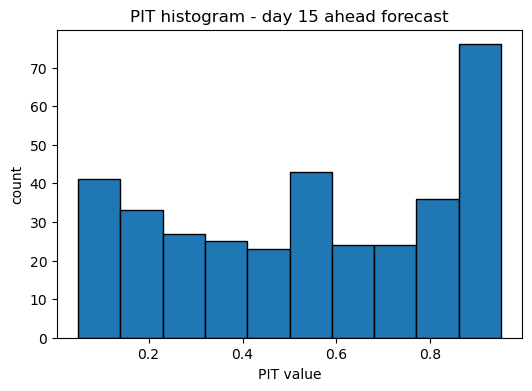

In [69]:
plt.figure(figsize=(6, 4))
plt.hist(pit_values, bins=10, edgecolor="black")
plt.xlabel("PIT value")
plt.ylabel("count")
plt.title("PIT histogram - day 15 ahead forecast")
plt.show()